# Step 2 — Hopfield Patterns and Similarity Analysis

**Project:** *When Memories Compete: How Similarity Affects Memory Retrieval in Hopfield Networks*

This notebook prepares the digit images as Hopfield patterns and measures how similar they are.
**No Hopfield network is built or trained here.**

Sections:
1. Load the data and convert it to Hopfield format (±1 vectors)
2. Define similarity (the *overlap*)
3. Similarity across the whole dataset
4. Within-class vs. between-class similarity
5. Bias: why even different digits look alike
6. Candidate memory sets: 5 real handwritten images, low vs. high similarity

In [2]:
import sys
from pathlib import Path
from itertools import combinations

import numpy as np
import matplotlib.pyplot as plt

# The loader lives in src/optdigits.py (the parser from notebook 01).
# Python looks for imports in the folders listed in sys.path, so add the project
# root to that list. This works whether Jupyter starts in notebooks/ or the root.
project_root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.optdigits import load_optdigits

images, labels = load_optdigits()
print("images:", images.shape, " labels:", labels.shape)

images: (946, 32, 32)  labels: (946,)


## 1. Convert to Hopfield format

A Hopfield network works with neurons in one of two states, **−1 or +1**, and does not use the image's 2D layout.
So each image needs two changes:

| step | from | to |
|---|---|---|
| map pixel values | 0 (background), 1 (ink) | −1, +1 using `2*x - 1` |
| flatten | 32 × 32 grid | vector of N = 1024 neurons |

The conversion is reversible: reshape a vector back to 32 × 32 to view it as an image.

In [3]:
N = 32 * 32   # number of neurons = number of pixels

def to_bipolar(imgs01):
    """0/1 images of shape (..., 32, 32) -> ±1 vectors of shape (..., 1024)."""
    flat = imgs01.reshape(*imgs01.shape[:-2], N)   # flatten the last two axes
    return (2 * flat.astype(np.int8) - 1)           # 0 -> -1, 1 -> +1

def to_image(vec):
    """±1 vector (1024,) -> 32x32 array, for plotting."""
    return vec.reshape(32, 32)

patterns = to_bipolar(images)   # shape (946, 1024)

print("patterns shape:", patterns.shape)
print("unique values :", np.unique(patterns))   # expect [-1  1]

# Check: converting back gives the original 0/1 image exactly.
assert np.array_equal((to_image(patterns[0]) + 1) // 2, images[0])
print("Round-trip check passed.")

patterns shape: (946, 1024)
unique values : [-1  1]
Round-trip check passed.


## 2. Measuring similarity: the overlap

The standard similarity measure in Hopfield theory is the **overlap** between two patterns $\xi$ and $\eta$:

$$m(\xi, \eta) = \frac{1}{N} \sum_{i=1}^{N} \xi_i \, \eta_i$$

Each neuron adds +1 if the two patterns agree there and −1 if they disagree, and the total is divided by N. So:

- **m = +1**: identical patterns
- **m = 0**: they agree on half the neurons (like two random patterns)
- **m = −1**: one pattern is the exact inverse of the other

Equivalently, m = 1 − 2 × (fraction of pixels that differ).

This same quantity will later measure retrieval: how close the network's final state is to a stored memory.

In [4]:
def overlap(a, b):
    """Overlap m between two ±1 vectors (a single number between -1 and 1)."""
    # Convert to float first: the patterns are int8, which only holds -128..127,
    # so summing 1024 products as int8 would overflow and give wrong answers.
    return np.dot(a.astype(np.float64), b.astype(np.float64)) / N

def overlap_matrix(P):
    """All pairwise overlaps for the rows of P. P @ P.T computes every dot product at once."""
    P = P.astype(np.float64)   # same reason as above: never multiply int8 patterns directly
    return P @ P.T / N

# Quick sanity checks on known cases
x = patterns[0]
print("m(x, x)       =", overlap(x, x))     # identical -> 1
print("m(x, -x)      =", overlap(x, -x))    # inverse   -> -1
rng = np.random.default_rng(0)
r1, r2 = rng.choice([-1, 1], N), rng.choice([-1, 1], N)
print(f"m(random, random) = {overlap(r1, r2):.3f}   (close to 0)")

m(x, x)       = 1.0
m(x, -x)      = -1.0
m(random, random) = -0.004   (close to 0)


### Numeric safety check

`patterns` is stored as `int8` to save memory, but an int8 can only hold values from −128 to 127.
A dot product of two 1024-neuron patterns can reach ±1024, so computing it in int8 **overflows silently**.
For example, `np.dot(x, x)` in int8 gives 0 instead of 1024.
Both overlap functions therefore convert to `float64` first. The cell below confirms that:
1. the naive int8 computation really does go wrong, so the risk is real;
2. our functions give exactly the same result as a safe 64-bit integer computation;
3. every self-overlap is exactly 1 and every value lies in [−1, 1].

In [5]:
# 1. Demonstrate the danger: int8 dot product of a pattern with itself
naive = np.dot(x, x)                       # computed in int8 -> overflows
print(f"naive int8 np.dot(x, x) = {naive}  (dtype {naive.dtype}); the correct value is {N}")

# 2. Compare against an exact integer reference (int64 cannot overflow here: max |value| = 1024)
P64 = patterns.astype(np.int64)
M_ref = (P64 @ P64.T) / N
M_all = overlap_matrix(patterns)           # every image vs every image, original order
print("overlap_matrix dtype:", M_all.dtype)
assert M_all.dtype == np.float64
assert np.array_equal(M_all, M_ref), "overlap_matrix disagrees with exact int64 reference"
assert all(overlap(patterns[i], patterns[j]) == M_ref[i, j] for i, j in [(0, 0), (0, 1), (5, 900)])

# 3. Range checks
assert np.all(np.diag(M_all) == 1.0), "self-overlap should be exactly 1"
assert M_all.min() >= -1 and M_all.max() <= 1
print(f"all {M_all.size:,} overlaps in [{M_all.min():.3f}, {M_all.max():.3f}], diagonal all 1.0")
print("Numeric safety checks passed.")

naive int8 np.dot(x, x) = 0  (dtype int8); the correct value is 1024
overlap_matrix dtype: float64
all 894,916 overlaps in [-0.012, 1.000], diagonal all 1.0
Numeric safety checks passed.


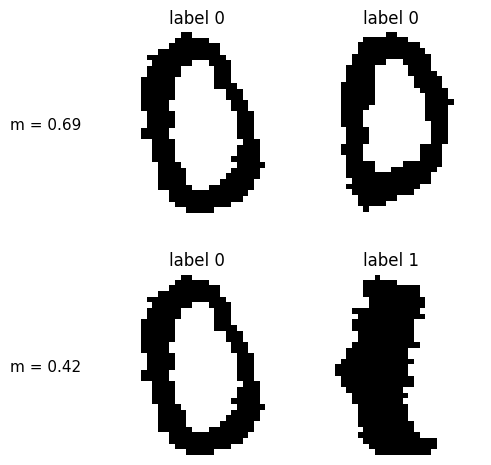

In [6]:
# Two real examples: two 0s, then a 0 and a 1.
i0a, i0b = np.where(labels == 0)[0][:2]
i1 = np.where(labels == 1)[0][0]

pairs = [(i0a, i0b), (i0a, i1)]
fig, axes = plt.subplots(2, 2, figsize=(5, 5))
for row, (i, j) in enumerate(pairs):
    for col, k in enumerate((i, j)):
        axes[row, col].imshow(to_image(patterns[k]), cmap="gray_r", vmin=-1, vmax=1)
        axes[row, col].set_title(f"label {labels[k]}")
        axes[row, col].axis("off")
    axes[row, 0].text(-5, 16, f"m = {overlap(patterns[i], patterns[j]):.2f}",
                      ha="right", va="center", fontsize=11)
plt.tight_layout()
plt.show()

## 3. Similarity across the whole dataset

Compute the overlap for **every pair of the 946 images** (a 946 × 946 matrix).
Images are sorted by label, so blocks of the same digit sit next to each other. If digits of one class resemble each other more than other digits, the diagonal blocks will be brighter.

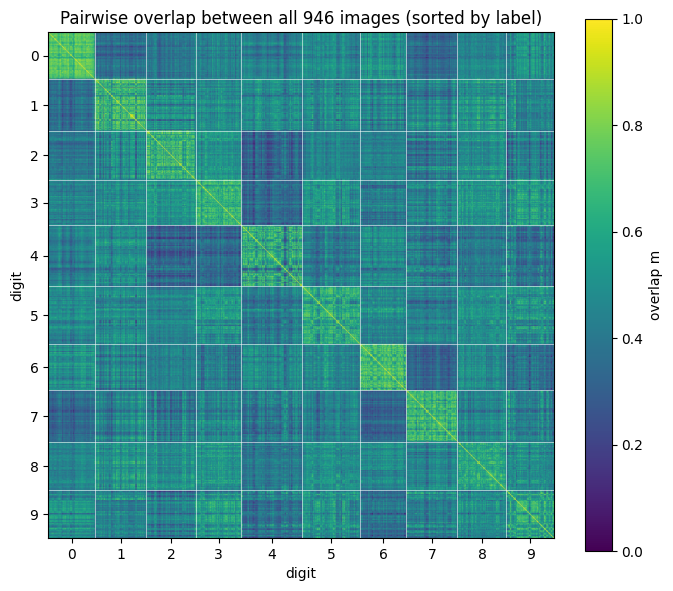

In [7]:
order = np.argsort(labels, kind="stable")   # indices that sort images by label
P_sorted = patterns[order]
L_sorted = labels[order]

M = overlap_matrix(P_sorted)   # (946, 946)

# Tick positions: the middle of each digit's block
counts = np.bincount(L_sorted, minlength=10)
edges = np.concatenate([[0], np.cumsum(counts)])
centers = (edges[:-1] + edges[1:]) / 2

plt.figure(figsize=(7, 6))
plt.imshow(M, cmap="viridis", vmin=0, vmax=1)
plt.colorbar(label="overlap m")
plt.xticks(centers, range(10)); plt.yticks(centers, range(10))
for e in edges[1:-1]:
    plt.axhline(e - 0.5, color="white", lw=0.4); plt.axvline(e - 0.5, color="white", lw=0.4)
plt.xlabel("digit"); plt.ylabel("digit")
plt.title("Pairwise overlap between all 946 images (sorted by label)")
plt.tight_layout()
plt.show()

The full matrix has too much detail to read, so summarise it: for each pair of digits (a, b), **average the overlap over all pairs of images** with one from class a and one from class b.
On the diagonal (a = a), skip each image's overlap with itself, which is always 1 and would inflate the average.

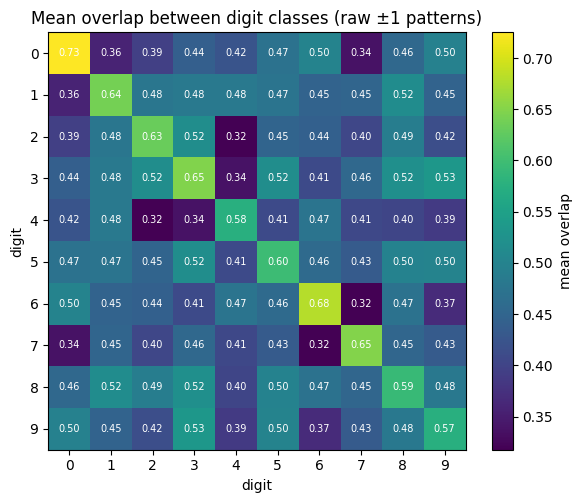

In [8]:
def class_mean_matrix(M, L):
    """10x10 matrix: average overlap between images of class a and images of class b."""
    C = np.zeros((10, 10))
    for a in range(10):
        for b in range(10):
            block = M[np.ix_(L == a, L == b)]   # sub-matrix: rows of class a, columns of class b
            if a == b:
                # drop the diagonal (self-overlaps)
                block = block[~np.eye(len(block), dtype=bool)]
            C[a, b] = block.mean()
    return C

def plot_digit_matrix(C, title, vmin=None, vmax=None, cmap="viridis", label="mean overlap"):
    plt.figure(figsize=(6, 5))
    plt.imshow(C, cmap=cmap, vmin=vmin, vmax=vmax)
    plt.colorbar(label=label)
    for a in range(10):
        for b in range(10):
            plt.text(b, a, f"{C[a, b]:.2f}", ha="center", va="center", fontsize=7, color="white")
    plt.xticks(range(10)); plt.yticks(range(10))
    plt.xlabel("digit"); plt.ylabel("digit")
    plt.title(title)
    plt.tight_layout()
    plt.show()

C_raw = class_mean_matrix(M, L_sorted)
plot_digit_matrix(C_raw, "Mean overlap between digit classes (raw ±1 patterns)")

## 4. Within-class vs. between-class similarity

Split all image pairs into two groups:
- **within-class**: both images are the same digit
- **between-class**: the images are different digits

Then compare the two overlap distributions.

within-class :  44684 pairs, mean overlap = 0.626
between-class: 402301 pairs, mean overlap = 0.442


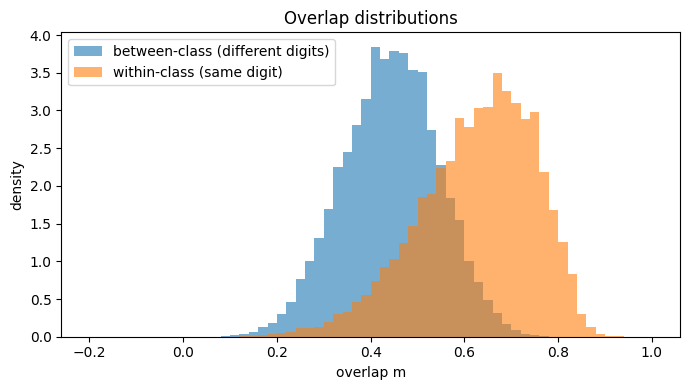

In [9]:
iu = np.triu_indices(len(M), k=1)          # each pair (i < j) once, no self-pairs
pair_m = M[iu]
same = L_sorted[iu[0]] == L_sorted[iu[1]]   # True if both images have the same label

within, between = pair_m[same], pair_m[~same]
print(f"within-class : {len(within):6d} pairs, mean overlap = {within.mean():.3f}")
print(f"between-class: {len(between):6d} pairs, mean overlap = {between.mean():.3f}")

bins = np.linspace(-0.2, 1, 61)
plt.figure(figsize=(7, 4))
plt.hist(between, bins=bins, density=True, alpha=0.6, label="between-class (different digits)")
plt.hist(within, bins=bins, density=True, alpha=0.6, label="within-class (same digit)")
plt.xlabel("overlap m"); plt.ylabel("density")
plt.title("Overlap distributions")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
# Most and least similar pairs of *different* digits (using the class means above)
digit_pairs = [(C_raw[a, b], a, b) for a, b in combinations(range(10), 2)]
digit_pairs.sort()

print("Least similar digit pairs:")
for m, a, b in digit_pairs[:5]:
    print(f"  {a} vs {b}: {m:.3f}")
print("Most similar digit pairs:")
for m, a, b in digit_pairs[::-1][:5]:
    print(f"  {a} vs {b}: {m:.3f}")

Least similar digit pairs:
  2 vs 4: 0.318
  6 vs 7: 0.319
  3 vs 4: 0.338
  0 vs 7: 0.338
  0 vs 1: 0.359
Most similar digit pairs:
  3 vs 9: 0.533
  3 vs 8: 0.520
  3 vs 5: 0.517
  2 vs 3: 0.517
  1 vs 8: 0.516


**Observation:** same-digit pairs overlap more than different-digit pairs, as expected.
But even *different* digits have a mean overlap around 0.45, far above the 0 of two random patterns. The next section explains why.

## 5. Bias: why even different digits look alike

Only about 30% of pixels are ink (+1), and the rest are background (−1).
Ink is also concentrated in the middle of the image, so the borders are background in almost every image.
Any two images therefore **agree on many background pixels**, whatever digit they show.

This matters for Hopfield networks: the classic theory assumes patterns with no correlation (overlap ≈ 0).
Shared background is a kind of similarity that has nothing to do with which digit is drawn.
Measuring it now lets us separate *digit-shape* similarity from *shared-background* similarity.

fraction of ink pixels p          = 0.305
expected overlap, random biased   = 0.151
observed mean between-class m     = 0.442
pixels that are background in >95% of images: 34.7%


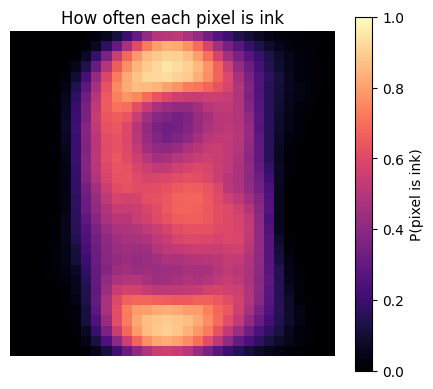

In [11]:
p_ink = images.mean()                # overall fraction of ink pixels
pixel_ink = images.mean(axis=0)      # per-pixel: how often each pixel is ink across all images

# If two patterns each had ink at random positions with probability p (independently),
# the expected overlap would be (1 - 2p)^2.
expected_random_biased = (1 - 2 * p_ink) ** 2

print(f"fraction of ink pixels p          = {p_ink:.3f}")
print(f"expected overlap, random biased   = {expected_random_biased:.3f}")
print(f"observed mean between-class m     = {between.mean():.3f}")
print(f"pixels that are background in >95% of images: {(pixel_ink < 0.05).mean():.1%}")

plt.figure(figsize=(4.5, 4))
plt.imshow(pixel_ink, cmap="magma", vmin=0, vmax=1)
plt.colorbar(label="P(pixel is ink)")
plt.title("How often each pixel is ink")
plt.axis("off")
plt.tight_layout()
plt.show()

Biased random patterns would give an expected overlap of only about 0.15. The observed ~0.45 is larger because ink is **concentrated in the same central region** of every image, as the heatmap shows.

**Bias-corrected similarity.** To focus on shape, first subtract the average ink level from the 0/1 pixels, then compute the normalised dot product (cosine similarity, similar to a correlation).
Pixels that are background in every image then contribute much less. We keep the **raw overlap** as the main measure, because that is what the Hopfield network will "see". The corrected version is a check that the digit ranking isn't just a background effect.

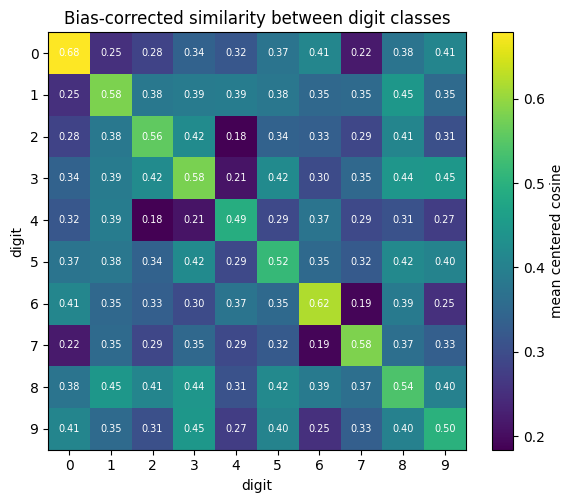

Rank agreement between raw and bias-corrected similarity (Spearman rho): 0.989


In [12]:
def centered_similarity_matrix(imgs01):
    """Cosine similarity of 0/1 images after subtracting the global mean ink level."""
    Z = imgs01.reshape(len(imgs01), N).astype(np.float64) - imgs01.mean()
    Z /= np.linalg.norm(Z, axis=1, keepdims=True)   # each row now has length 1
    return Z @ Z.T

M_c = centered_similarity_matrix(images[order])
C_centered = class_mean_matrix(M_c, L_sorted)
plot_digit_matrix(C_centered, "Bias-corrected similarity between digit classes",
                  label="mean centered cosine")

# Do the two measures rank the 45 digit pairs in the same order?
# Spearman rank correlation = Pearson correlation of the ranks.
ab = list(combinations(range(10), 2))
raw_vals = np.array([C_raw[a, b] for a, b in ab])
cen_vals = np.array([C_centered[a, b] for a, b in ab])
rank = lambda v: np.argsort(np.argsort(v))
rho = np.corrcoef(rank(raw_vals), rank(cen_vals))[0, 1]
print(f"Rank agreement between raw and bias-corrected similarity (Spearman rho): {rho:.3f}")

If the rank correlation is close to 1, both measures put the digit pairs in nearly the same order, from least to most similar.
In that case the raw overlap is a fair way to rank similarity, even though its absolute values are inflated by shared background.

## 6. Candidate memory sets: 5 real handwritten images

The main experiments will store a **set of memories** and ask whether the network can still retrieve each one.
The key manipulation is **how similar the memories in a set are**.

Each candidate set is **5 actual handwritten images** from the dataset, not averaged or idealised patterns.

Rules:
- **5 images, each a different digit.** Every stored memory is then a distinct digit, so later we can tell which memory the network retrieved.
- **Set similarity** = the mean of the overlaps between all 10 pairs of images in the set, using the raw overlap matrix `M_all` (the network works on the raw ±1 patterns).

- **Only typical images are allowed.** Without this rule, the high-similarity search picks oddly drawn images: thick, narrow blobs that are "similar" only because they fill the same central column, and are barely readable as digits.
  So each image gets a **typicality** score: its mean overlap with the other images of the same digit. Only the more typical half of each digit (score at or above that digit's median) can be chosen.

There are far too many possible 5-image sets to try them all, so we use a simple **greedy search**:
1. Start with the pair of images (different digits) that has the lowest overlap (low set) or the highest (high set).
2. Repeatedly add the image, from a digit not yet used, whose mean overlap with the images already chosen is lowest (low set) or highest (high set).
3. Stop at 5 images.

In [13]:
SET_SIZE = 5

def set_similarity(idx, Msim):
    """Mean pairwise similarity among the images with indices idx."""
    return np.mean([Msim[i, j] for i, j in combinations(idx, 2)])

def greedy_set(Msim, labels, size, mode):
    """Greedily choose `size` images with distinct labels and low ("low") or high ("high") mutual similarity."""
    sign = 1.0 if mode == "high" else -1.0
    score = sign * Msim                               # always maximise `score`

    # Step 1: best starting pair. Rule out self-pairs and same-digit pairs with -inf.
    pair_score = score.copy()
    pair_score[labels[:, None] == labels[None, :]] = -np.inf
    i, j = np.unravel_index(np.argmax(pair_score), pair_score.shape)
    chosen = [i, j]

    # Step 2: keep adding the best image from a digit not yet in the set.
    while len(chosen) < size:
        allowed = ~np.isin(labels, labels[chosen])           # images of unused digits
        mean_to_chosen = score[:, chosen].mean(axis=1)       # each image's mean score vs. the chosen ones
        mean_to_chosen[~allowed] = -np.inf
        chosen.append(int(np.argmax(mean_to_chosen)))

    return np.array(chosen)

# Typicality: each image's mean overlap with the OTHER images of its own digit.
typicality = np.zeros(len(labels))
for i in range(len(labels)):
    same_digit = (labels == labels[i])
    same_digit[i] = False                     # leave out the image itself
    typicality[i] = M_all[i, same_digit].mean()

# Candidate pool: the more typical half of each digit
in_pool = np.zeros(len(labels), dtype=bool)
for d in range(10):
    idx_d = np.where(labels == d)[0]
    in_pool[idx_d] = typicality[idx_d] >= np.median(typicality[idx_d])
pool = np.where(in_pool)[0]                   # original indices of the allowed images
print(f"candidate pool: {len(pool)} of {len(labels)} images")

# Run the greedy search inside the pool, then map back to original image indices.
M_pool = M_all[np.ix_(pool, pool)]
low_idx = pool[greedy_set(M_pool, labels[pool], SET_SIZE, "low")]
high_idx = pool[greedy_set(M_pool, labels[pool], SET_SIZE, "high")]

# Bias-corrected similarity for every image pair (original order), as a cross-check
M_c_all = centered_similarity_matrix(images)

for name, idx in [("LOW ", low_idx), ("HIGH", high_idx)]:
    print(f"{name} set: image indices {idx.tolist()}, digits {labels[idx].tolist()}")
    print(f"      mean overlap m = {set_similarity(idx, M_all):.3f}   "
          f"bias-corrected = {set_similarity(idx, M_c_all):.3f}   "
          f"ink fraction per image = {[round(float(images[k].mean()), 2) for k in idx]}")

candidate pool: 476 of 946 images
LOW  set: image indices [226, 813, 365, 386, 127], digits [4, 2, 9, 7, 6]
      mean overlap m = 0.292   bias-corrected = 0.171   ink fraction per image = [0.33, 0.36, 0.27, 0.3, 0.3]
HIGH set: image indices [608, 629, 877, 534, 689], digits [1, 8, 2, 3, 5]
      mean overlap m = 0.657   bias-corrected = 0.619   ink fraction per image = [0.38, 0.38, 0.32, 0.34, 0.28]


### Are these sets really extreme? Compare with random sets

To see how unusual the chosen sets are, draw 5,000 **random** sets under the same rules (5 different digits, one random image of each from the typical pool) and plot the distribution of their similarity.

random sets: mean m = 0.462, range [0.327, 0.596]
LOW set  m = 0.292  -> lower than 100.0% of random sets
HIGH set m = 0.657  -> higher than 100.0% of random sets


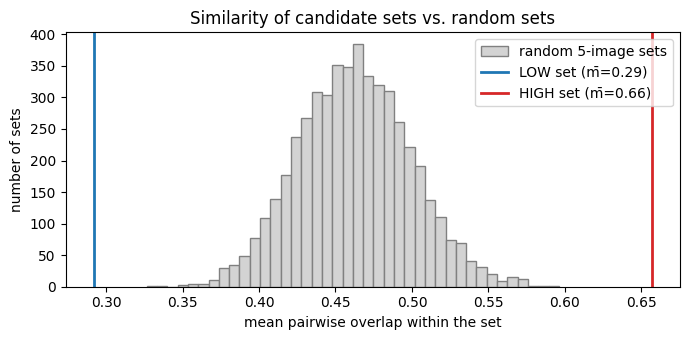

In [14]:
rng = np.random.default_rng(42)   # fixed seed so the result is reproducible
idx_by_digit = [pool[labels[pool] == d] for d in range(10)]   # typical images of each digit

random_scores = []
for _ in range(5000):
    digits = rng.choice(10, SET_SIZE, replace=False)            # 5 different digits
    idx = [rng.choice(idx_by_digit[d]) for d in digits]         # one random image of each
    random_scores.append(set_similarity(idx, M_all))
random_scores = np.array(random_scores)

low_m, high_m = set_similarity(low_idx, M_all), set_similarity(high_idx, M_all)
print(f"random sets: mean m = {random_scores.mean():.3f}, "
      f"range [{random_scores.min():.3f}, {random_scores.max():.3f}]")
print(f"LOW set  m = {low_m:.3f}  -> lower than {np.mean(random_scores > low_m):.1%} of random sets")
print(f"HIGH set m = {high_m:.3f}  -> higher than {np.mean(random_scores < high_m):.1%} of random sets")

plt.figure(figsize=(7, 3.5))
plt.hist(random_scores, bins=40, color="lightgray", edgecolor="gray", label="random 5-image sets")
plt.axvline(low_m, color="tab:blue", lw=2, label=f"LOW set (m̄={low_m:.2f})")
plt.axvline(high_m, color="tab:red", lw=2, label=f"HIGH set (m̄={high_m:.2f})")
plt.xlabel("mean pairwise overlap within the set"); plt.ylabel("number of sets")
plt.title("Similarity of candidate sets vs. random sets")
plt.legend()
plt.tight_layout()
plt.show()

### Look at the chosen images and their pairwise overlaps

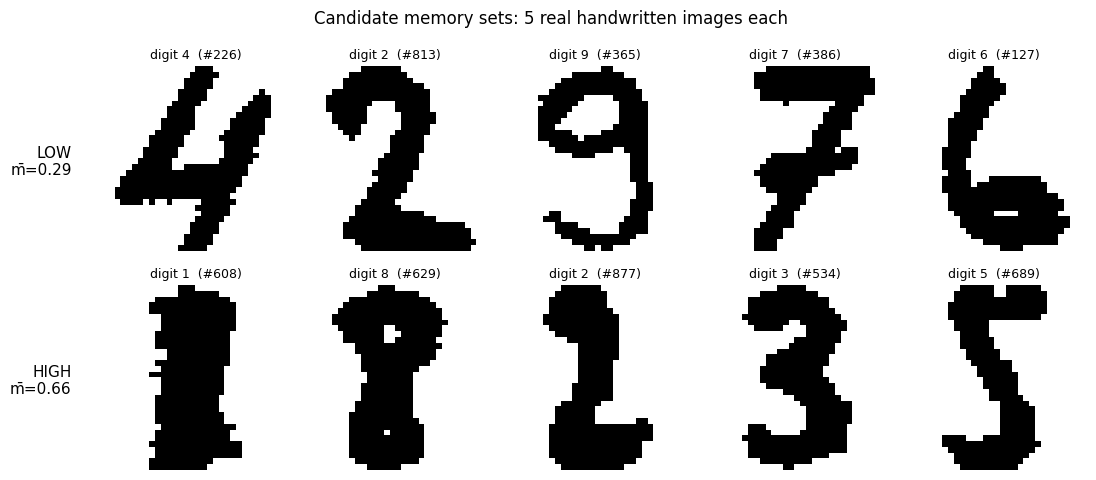

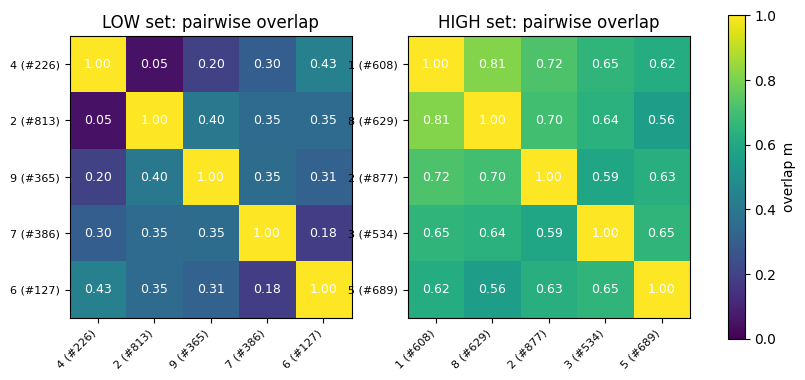

In [15]:
fig, axes = plt.subplots(2, SET_SIZE, figsize=(2.2 * SET_SIZE, 5))
for row, (name, idx) in enumerate([("LOW", low_idx), ("HIGH", high_idx)]):
    for col, k in enumerate(idx):
        ax = axes[row, col]
        ax.imshow(images[k], cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(f"digit {labels[k]}  (#{k})", fontsize=9)
        ax.axis("off")
    axes[row, 0].text(-6, 16, f"{name}\nm̄={set_similarity(idx, M_all):.2f}",
                      ha="right", va="center", fontsize=11)
fig.suptitle("Candidate memory sets: 5 real handwritten images each")
plt.tight_layout()
plt.show()

# 5x5 overlap matrix within each set
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (name, idx) in zip(axes, [("LOW", low_idx), ("HIGH", high_idx)]):
    sub = M_all[np.ix_(idx, idx)]
    im = ax.imshow(sub, cmap="viridis", vmin=0, vmax=1)
    for a in range(SET_SIZE):
        for b in range(SET_SIZE):
            ax.text(b, a, f"{sub[a, b]:.2f}", ha="center", va="center", color="white", fontsize=9)
    ticks = [f"{labels[k]} (#{k})" for k in idx]
    ax.set_xticks(range(SET_SIZE)); ax.set_xticklabels(ticks, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(SET_SIZE)); ax.set_yticklabels(ticks, fontsize=8)
    ax.set_title(f"{name} set: pairwise overlap")
fig.colorbar(im, ax=axes, label="overlap m")
plt.show()

## Summary

- Each image is now a **±1 vector of 1024 neurons**, ready for a Hopfield network.
- **Overlap m** is our similarity measure, and it will also score retrieval later. It is always computed in `float64`, because int8 arithmetic silently overflows. This is checked explicitly in section 2.
- Same-digit images are more similar than different-digit images, but **all patterns share a large background bias**, so even different digits overlap far above 0.
- The bias-corrected measure ranks digit pairs in nearly the same order as the raw overlap.
- Two **candidate memory sets of 5 real handwritten images** (5 different digits each, typical images only) were chosen by greedy search. They sit at the extreme low and high ends of the similarity distribution of random sets.

**Next (step 3, not started):** implement the Hopfield network (Hebbian storage + recall) and test it on these sets.